## 11 - Single-Cell Reference Probe Validation (XDec Stage 0)

### Aim
* Visualize the Peng et al. single-cell reference's expression profile restricted to XDec's 344 Stage-0
  selected probes, and check whether that probe set alone can clearly distinguish the reference's 10
  labeled cell types - a heatmap of the raw material Stage 1 deconvolution runs on, never previously
  inspected on its own in this repository.

### Input
* `data/deconvolution/xdec/refs.tsv` - Peng et al. 2019 single-cell reference, 17,004 genes x 2,748 cells
  (10 cell types, 35 patients).
* `data/deconvolution/xdec/ref_metadata.tsv` - `Cell_Type` label per cell.
* `data/deconvolution/xdec/stage0/selected_probes.txt` - 344-gene one-vs-rest informative set chosen by
  XDec Stage 0 (`04_xdec_deconvolution.ipynb`).

### Output
* `data/deconvolution/xdec/figures/stage0_probe_heatmap_single_cell_sorted.png` - single-cell-level heatmap,
  344 probes (rows) x 2,748 cells (columns, sorted by cell type, not clustered).

### Steps
* Subset `refs.tsv` to the 344 selected probes (all 344 present) and sort cells (columns) purely by
  `Cell_Type` label - a fixed sort, not a clustering algorithm's choice.
* Z-score each probe across all cells and plot the sorted single-cell heatmap (rows hierarchically clustered
  for visual grouping only; columns never reordered), with a cell-type color bar on top.

### Result
* With columns sorted strictly by cell type, 8 of 10 type blocks show a visually distinct band of probes
  elevated only within that block - T cell, blood vessel endothelial, enteroendocrine, fibroblast, myeloid
  leukocyte, neural, pancreatic acinar, and pancreatic ductal cell all have clean one-vs-rest signal visible
  by eye.
* Two pairs do not separate cleanly: lymphocyte of B lineage does not get its own distinct band - its
  elevated rows largely overlap the T-cell block - and pancreatic stellate cell's elevated rows overlap the
  fibroblast block.

### Conclusion
* The 344 Stage-0 probes clearly distinguish most (8/10) of the reference's cell types by eye in this sorted
  heatmap. The two exceptions - T cell vs. B-lineage lymphocyte, and fibroblast vs. pancreatic stellate cell
  - share lineage (lymphoid and mesenchymal/stromal, respectively) and do not show distinct blocks here,
  consistent with the same confusions notebooks 09 and 10 already reported downstream of deconvolution.


### What this notebook checks

XDec's Stage 0 (`04_xdec_deconvolution.ipynb`) ran a one-vs-rest t-test over the Peng et al. 2019 single-cell
pancreatic reference (`refs.tsv` / `ref_metadata.tsv`, 10 cell types, 35 patients) and picked 344 genes
(`stage0/selected_probes.txt`) as the "informative" probe set that Stage 1 then uses to fit cell-type
proportions. That selection has never itself been visually inspected in this repository - notebook 10 uses
the same 344 genes downstream (correlating *XDec output profiles* against the reference), but does not check
whether the probe set actually separates the reference's own cell types *before* any deconvolution is run.

Here: subset the single-cell reference to just these 344 genes, z-score each gene across all 2,748 cells, and
sort the heatmap's columns by cell type (not hierarchically clustered - a direct visual check of block
structure).

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# This notebook lives in progress/scripts/ - Jupyter starts the kernel with cwd = the
# notebook's own folder, so one level up reaches progress/, where every "data/..." path
# below is relative to (same convention as notebooks 04/07/08/09/10).
if os.path.basename(os.getcwd()) == "scripts":
    os.chdir("..")

XDEC_DIR = "data/deconvolution/xdec"
FIG_DIR = os.path.join(XDEC_DIR, "figures")
os.makedirs(FIG_DIR, exist_ok=True)

refs = pd.read_csv(os.path.join(XDEC_DIR, "refs.tsv"), sep="\t", index_col=0)
ref_meta = pd.read_csv(os.path.join(XDEC_DIR, "ref_metadata.tsv"), sep="\t", index_col=0)
probes = [g.strip() for g in open(os.path.join(XDEC_DIR, "stage0", "selected_probes.txt"))]

print("refs:", refs.shape, " ref_meta:", ref_meta.shape, " probes:", len(probes))
ref_meta["Cell_Type"].value_counts()

refs: (17004, 2748)  ref_meta: (2748, 1)  probes: 344


Cell_Type
T cell                           300
blood vessel endothelial cell    300
enteroendocrine cell             300
fibroblast                       300
lymphocyte of B lineage          300
myeloid leukocyte                300
pancreatic acinar cell           300
pancreatic ductal cell           300
pancreatic stellate cell         300
neural cell                       48
Name: count, dtype: int64

### Step 1: subset to the 344 selected probes and order cells by type

Columns are single cells (`<patient>_<10x barcode>`); keep only cells with a known `Cell_Type` and restrict rows
to probes present in `refs.tsv`. Columns are then sorted purely by `Cell_Type` (alphabetical, ties broken by
patient then barcode) - a fixed sort, not a clustering algorithm's choice - so the heatmap's column blocks are
exactly the reference's own type labels.

In [2]:
valid_probes = [g for g in probes if g in refs.index]
print(f"{len(valid_probes)}/{len(probes)} selected probes present in refs.tsv")

ref_sub = refs.loc[valid_probes]
ref_sub = ref_sub[[c for c in ref_sub.columns if c in ref_meta.index]]
cell_types = ref_meta.loc[ref_sub.columns, "Cell_Type"]

order = cell_types.sort_values(kind="stable").index
ref_sorted = ref_sub[order]
cell_types_sorted = cell_types.loc[order]

print(f"{ref_sorted.shape[1]} single cells x {ref_sorted.shape[0]} probes, "
      f"sorted into {cell_types_sorted.nunique()} cell-type blocks")
cell_types_sorted.value_counts()

344/344 selected probes present in refs.tsv
2748 single cells x 344 probes, sorted into 10 cell-type blocks


Cell_Type
T cell                           300
blood vessel endothelial cell    300
enteroendocrine cell             300
fibroblast                       300
lymphocyte of B lineage          300
myeloid leukocyte                300
pancreatic acinar cell           300
pancreatic ductal cell           300
pancreatic stellate cell         300
neural cell                       48
Name: count, dtype: int64

### Step 2: z-score each probe across cells and plot the sorted heatmap

Raw TPM/counts span several orders of magnitude across genes, so each probe (row) is z-scored across all 2,748
cells before plotting (standard for marker-gene heatmaps) - this puts every gene on the same color scale so a
cell type's signature is visible as a block of warm color, regardless of that gene's absolute expression level.
Rows (probes) are hierarchically clustered purely for visual grouping of co-expressed genes; columns (cells)
stay in the fixed cell-type sort from Step 1 - never reordered by clustering.

344/344 probes kept after dropping zero-variance rows


/Users/liruixi/.pixi/envs/python/lib/python3.12/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


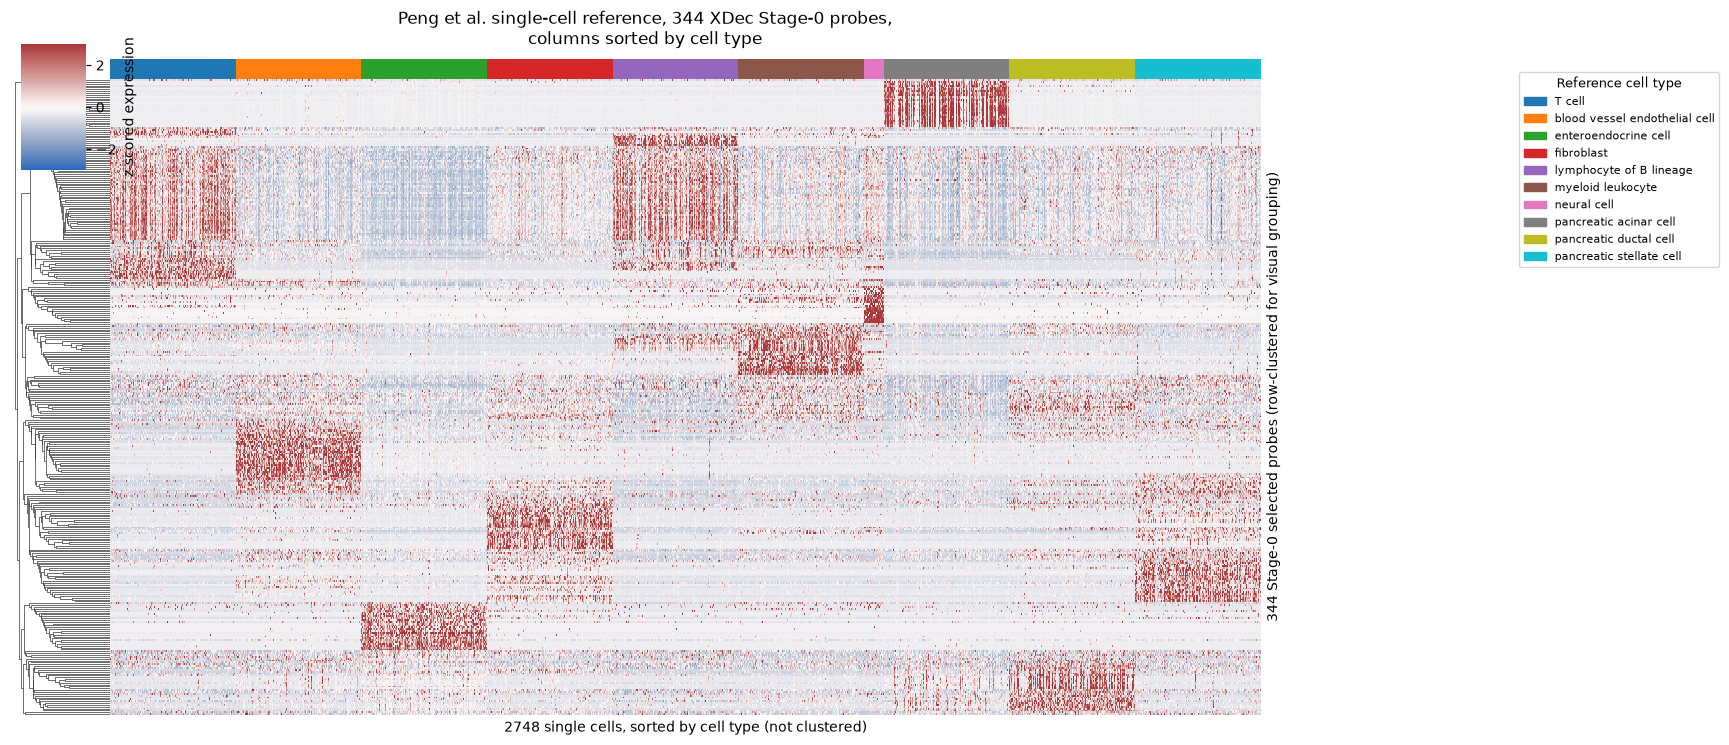

saved: data/deconvolution/xdec/figures/stage0_probe_heatmap_single_cell_sorted.png


In [3]:
zscored = ref_sorted.sub(ref_sorted.mean(axis=1), axis=0).div(ref_sorted.std(axis=1).replace(0, np.nan), axis=0)
zscored = zscored.dropna(how="any")
print(f"{zscored.shape[0]}/{ref_sorted.shape[0]} probes kept after dropping zero-variance rows")

type_order = sorted(cell_types_sorted.unique())
palette = dict(zip(type_order, sns.color_palette("tab10", n_colors=len(type_order))))
col_colors = cell_types_sorted.map(palette)
col_colors.name = "Cell type"

g = sns.clustermap(
    zscored, row_cluster=True, col_cluster=False,
    col_colors=col_colors.values,
    cmap="vlag", vmin=-3, vmax=3, center=0,
    xticklabels=False, yticklabels=False,
    figsize=(13, 7), cbar_kws={"label": "z-scored expression"},
    dendrogram_ratio=(0.08, 0.02),
)
g.ax_heatmap.set_xlabel(f"{zscored.shape[1]} single cells, sorted by cell type (not clustered)")
g.ax_heatmap.set_ylabel(f"{zscored.shape[0]} Stage-0 selected probes (row-clustered for visual grouping)")

handles = [plt.Rectangle((0, 0), 1, 1, color=palette[t]) for t in type_order]
g.ax_heatmap.legend(handles, type_order, title="Reference cell type",
                     bbox_to_anchor=(1.22, 1.02), loc="upper left", fontsize=8, title_fontsize=9)
g.fig.suptitle("Peng et al. single-cell reference, 344 XDec Stage-0 probes,\ncolumns sorted by cell type",
               y=1.03)

out_path = os.path.join(FIG_DIR, "stage0_probe_heatmap_single_cell_sorted.png")
g.savefig(out_path, dpi=200, bbox_inches="tight")
plt.show()
print("saved:", out_path)

### Interpretation

With columns sorted strictly by cell type, 8 of 10 type blocks show at least one visually distinct band of
probes elevated (dark red) only within that block - T cell, blood vessel endothelial, enteroendocrine,
fibroblast, myeloid leukocyte, neural, pancreatic acinar, and pancreatic ductal cell all have clean one-vs-rest
signal visible by eye. Lymphocyte of B lineage does not get its own clean band - its elevated rows largely
overlap the T-cell block - and pancreatic stellate cell's elevated rows overlap the fibroblast block.

**Bottom line**: the 344 Stage-0 probes clearly distinguish cell types for 8 of 10 reference classes by eye.
The exceptions - T cell vs. B-lineage lymphocyte, and fibroblast vs. pancreatic stellate cell - share lineage
(lymphoid and mesenchymal/stromal, respectively), matching the same confusions notebooks 09 and 10 already
reported downstream of deconvolution.